Automotive

In [2]:
import pandas as pd 
import numpy as np

In [3]:
#Importing the dataset
reg_path= "../../data/Regression_datasets/automotive.csv"
auto_reg_data= pd.read_csv(reg_path)
print(auto_reg_data.head())

       speed  acceleration   braking    mileage
0  34.157772      1.603424  0.931736  37.611989
1  49.707256      1.806978  2.186822  33.145521
2  52.325752      2.620780  1.648655  32.637948
3  84.175511      1.895130  2.408249  26.080386
4  43.492926      3.105762  2.128474  31.454574


In [4]:
#shape
auto_reg_data.shape

(10000, 4)

In [5]:
#describe
auto_reg_data.describe()

,speed,acceleration,braking,mileage
count,10000.000000,10000.000000,10000.000000,10000.000000
mean,59.905726,2.993318,1.996655,29.064207
std,15.182827,0.981655,0.499470,4.210561
min,-3.408477,-0.876122,0.170823,14.399174
25%,49.572965,2.327770,1.664892,26.251110
50%,59.889755,3.006794,1.997726,29.054046
75%,70.279504,3.663331,2.331981,31.856791
max,117.065856,6.549518,3.775330,49.242460


In [25]:
def data_exploration(data):
    print("Data Exploration:")
    print("Shape of the dataset:", data.shape)
    print("\nColumns in the dataset:", data.columns)
    print("\nData types of each column:\n", data.dtypes)
    print("\nMissing values in each column:\n", data.isnull().sum())
    print("\nStatistical summary of the dataset:\n", data.describe())

def get_correlation_matrix(data):
    correlation_matrix = data.corr()
    return correlation_matrix

def plot_correlation_matrix(correlation_matrix):
    import matplotlib.pyplot as plt
    import seaborn as sns

    plt.figure(figsize=(6, 4))
    sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm', cbar=True)
    plt.title("Correlation Matrix")
    plt.show()

def feature_selection(data, target_variable):
    from sklearn.feature_selection import SelectKBest, f_regression

    X = data.drop(columns=[target_variable])
    y = data[target_variable]

    # Select the top 5 features based on univariate linear regression tests
    selector = SelectKBest(score_func=f_regression, k=5)
    selector.fit(X, y)

    selected_features = X.columns[selector.get_support()]
    return selected_features

def normalize_data(data):
    from sklearn.preprocessing import MinMaxScaler

    scaler = MinMaxScaler()
    normalized_data = pd.DataFrame(scaler.fit_transform(data), columns=data.columns)
    return normalized_data

def handle_missing_values(data):
    # Fill missing values with the mean of the column
    data_filled = data.fillna(data.mean())
    return data_filled

def linear_regression_model(X, y):
    from sklearn.model_selection import train_test_split
    from sklearn.linear_model import LinearRegression
    from sklearn.metrics import mean_squared_error, r2_score

    # Split the dataset into training and testing sets
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # Create a linear regression model
    model = LinearRegression()
    model.fit(X_train, y_train)

    # Make predictions on the test set
    y_pred = model.predict(X_test)

    # Evaluate the model
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    print("Mean Squared Error:", mse)
    print("R-squared:", r2)

    return model

def cross_validation(model, X, y, cv=5):
    from sklearn.model_selection import cross_val_score

    scores = cross_val_score(model, X, y, cv=cv)
    print("Cross-validation scores:", scores)
    print("Average CV score:", scores.mean())

In [7]:
data_exploration(auto_reg_data)

Data Exploration:
Shape of the dataset: (10000, 4)

Columns in the dataset: Index(['speed', 'acceleration', 'braking', 'mileage'], dtype='object')

Data types of each column:
 speed           float64
acceleration    float64
braking         float64
mileage         float64
dtype: object

Missing values in each column:
 speed           0
acceleration    0
braking         0
mileage         0
dtype: int64

Statistical summary of the dataset:
               speed  acceleration       braking       mileage
count  10000.000000  10000.000000  10000.000000  10000.000000
mean      59.905726      2.993318      1.996655     29.064207
std       15.182827      0.981655      0.499470      4.210561
min       -3.408477     -0.876122      0.170823     14.399174
25%       49.572965      2.327770      1.664892     26.251110
50%       59.889755      3.006794      1.997726     29.054046
75%       70.279504      3.663331      2.331981     31.856791
max      117.065856      6.549518      3.775330     49.242460


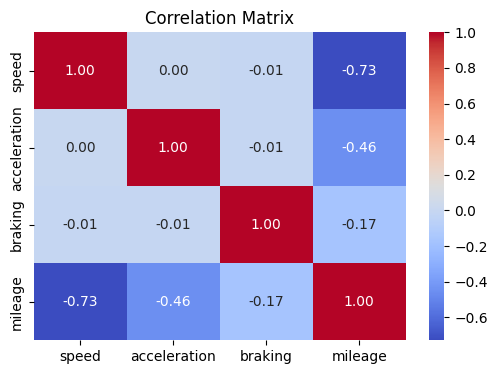

In [16]:
correlation_matrix = get_correlation_matrix(auto_reg_data)
plot_correlation_matrix(correlation_matrix)

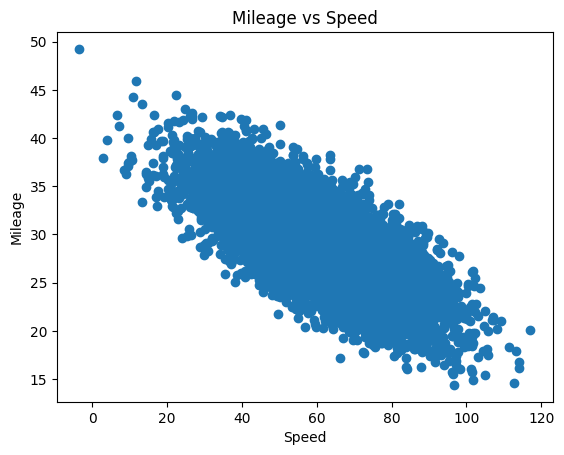

In [21]:
#scatter plot of mileage vs engine size
import matplotlib.pyplot as plt
plt.scatter(auto_reg_data['speed'], auto_reg_data['mileage'])
plt.title('Mileage vs Speed')
plt.xlabel('Speed')
plt.ylabel('Mileage')
plt.show()


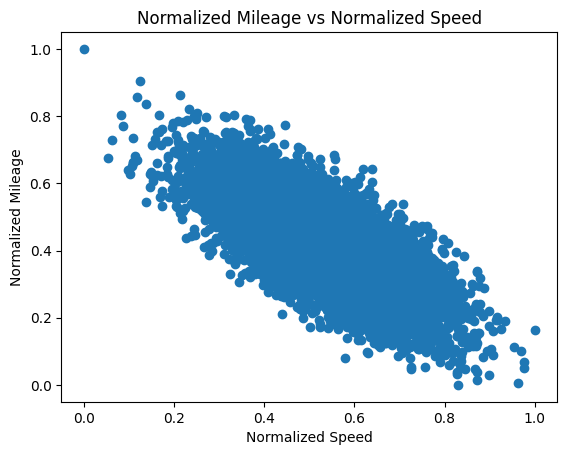

In [22]:
#normalize the data and scatterplot of normalized mileage vs normalized speed
normalized_data = normalize_data(auto_reg_data)
plt.scatter(normalized_data['speed'], normalized_data['mileage'])
plt.title('Normalized Mileage vs Normalized Speed')
plt.xlabel('Normalized Speed')
plt.ylabel('Normalized Mileage')
plt.show()


#Speed and milage have negative correlation -0.73 or -73%.
#accelaration and milege correlation -0.46 04 -46%


In [19]:
#linear regression model using scikit-learn

x=auto_reg_data.drop(columns=['mileage'], axis=1)
y=auto_reg_data['mileage']

model = linear_regression_model(x, y)

Mean Squared Error: 4.013272509084403
R-squared: 0.7632613152597927


/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


In [23]:
#cross-validation of the linear regression model


from sklearn.model_selection import cross_val_score


scores = cross_val_score(model, x, y, cv=5)
print("Cross-validation scores:", scores)
print("Average CV score:", scores.mean())

Cross-validation scores: [0.76007082 0.77014261 0.77129596 0.77691291 0.77249068]
Average CV score: 0.7701825955202303


/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: i

after applying cv we can predict accuracy upto 77%

In [29]:
x_normalized = normalized_data.drop(columns=['mileage'], axis=1)
y_normalized = normalized_data['mileage']

nor_model = linear_regression_model(x_normalized, y_normalized)


Mean Squared Error: 0.003305677082974624
R-squared: 0.7632613152597927


/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


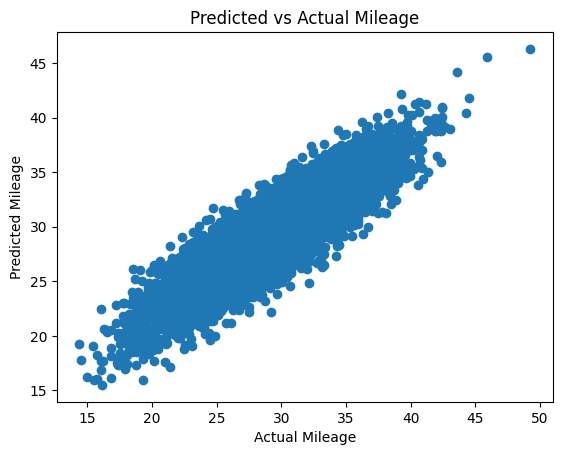

In [26]:
#plot scatter plot of predicted vs actual mileage
y_pred = model.predict(x)
plt.scatter(y, y_pred)
plt.title('Predicted vs Actual Mileage')
plt.xlabel('Actual Mileage')
plt.ylabel('Predicted Mileage') 
plt.show()

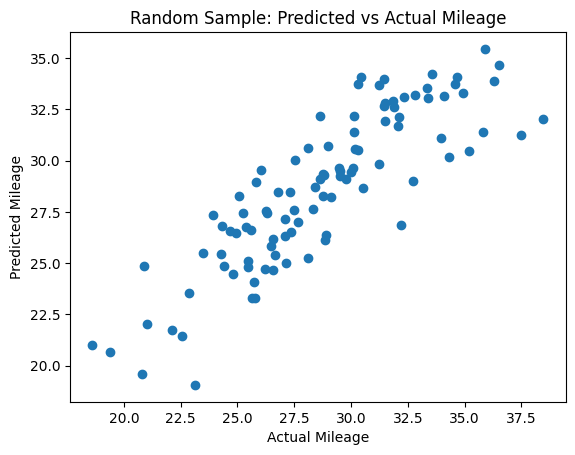

In [28]:
#random selection of 5 rows from the dataset
random_rows = zip(y_pred, y)
ran_data = pd.DataFrame(random_rows, columns=['Predicted Mileage', 'Actual Mileage']).sample(n=100)

plt.scatter(ran_data['Actual Mileage'], ran_data['Predicted Mileage'])
plt.title('Random Sample: Predicted vs Actual Mileage')
plt.xlabel('Actual Mileage')
plt.ylabel('Predicted Mileage')
plt.show()

#Finally 77% percent we can confident predicting milege of car